# Simple Linear Regression — Gradient Descent & Convergence

In this lecture, we will implement gradient descent for the simplified linear regression example.

### Learning objectives

- Understand the gradient descent update rule.
- Calculate the derivative of the cost function.
- Observe how the learning rate affects parameter updates.
- Track cost across iterations.
- Understand convergence.

We will keep the intercept fixed at zero and update only the slope.

$$
J(\theta_1)=\frac{7}{6}(\theta_1-1)^2
$$

## 1. Gradient Descent Update Rule

The general update rule is:

$$
\theta_j \leftarrow
\theta_j-\alpha\frac{\partial J(\theta)}{\partial\theta_j}
$$

For our simplified example, only the slope changes:

$$
\theta_1 \leftarrow
\theta_1-\alpha\frac{dJ}{d\theta_1}
$$

The derivative tells us the direction of cost change, while the learning rate controls the update size.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Sample dataset
data = pd.DataFrame({
    "x": [1, 2, 3],
    "y": [1, 2, 3]
})


def predict_output(x, theta_0, theta_1):
    return theta_0 + theta_1 * x


def compute_cost(x, y, theta_0, theta_1):
    predictions = predict_output(x, theta_0, theta_1)
    errors = predictions - y

    m = len(y)
    cost = np.sum(errors ** 2) / (2 * m)

    return cost

In [2]:
# Cost function:
# J(theta_1) = (7/6) * (theta_1 - 1)**2
#
# Derivative:
# dJ/dtheta_1 = (7/3) * (theta_1 - 1)

def compute_gradient(theta_1):
    """
    Compute the derivative of the cost function
    for the simplified dataset.
    """
    return (7 / 3) * (theta_1 - 1)


# Test the gradient at different slopes
for slope in [0, 0.5, 1, 2]:
    print(
        f"Slope = {slope:>3} | "
        f"Gradient = {compute_gradient(slope):.4f}"
    )

Slope =   0 | Gradient = -2.3333
Slope = 0.5 | Gradient = -1.1667
Slope =   1 | Gradient = 0.0000
Slope =   2 | Gradient = 2.3333


### Interpreting the Gradient

- When $\theta_1 < 1$, the gradient is negative. Gradient descent increases the slope.
- When $\theta_1 > 1$, the gradient is positive. Gradient descent decreases the slope.
- When $\theta_1 = 1$, the gradient is zero.

The minimum occurs at $\theta_1=1$, where the cost is zero.

In [3]:
def gradient_descent(
    initial_theta_1,
    learning_rate,
    iterations
):
    """
    Minimize the cost function by updating theta_1.

    The intercept remains fixed at zero.
    """
    theta_1 = float(initial_theta_1)

    history = []

    for iteration in range(iterations + 1):
        cost = compute_cost(
            data["x"],
            data["y"],
            theta_0=0,
            theta_1=theta_1
        )

        gradient = compute_gradient(theta_1)

        history.append({
            "Iteration": iteration,
            "Slope": theta_1,
            "Gradient": gradient,
            "Cost": cost
        })

        if iteration == iterations:
            break

        theta_1 = theta_1 - learning_rate * gradient

    return theta_1, pd.DataFrame(history)


# Example run
final_slope, history = gradient_descent(
    initial_theta_1=0,
    learning_rate=0.1,
    iterations=20
)

print(f"Final slope: {final_slope:.6f}")
print(f"Final cost:  {history['Cost'].iloc[-1]:.8f}")

history.head()

Final slope: 0.995078
Final cost:  0.00005652


,Iteration,Slope,Gradient,Cost
0,0,0.000000,-2.333333,2.333333
1,1,0.233333,-1.788889,1.371481
2,2,0.412222,-1.371481,0.806126
3,3,0.549370,-1.051469,0.473823
4,4,0.654517,-0.806126,0.278503


## 2. Observe Parameter Updates

Each iteration:

1. Calculates the current cost.
2. Calculates the gradient at the current slope.
3. Updates the slope.
4. Records the results.

Notice how the slope approaches $1$ and the cost decreases.

This is an illustrative numerical implementation of gradient descent, rather than a call to a machine learning library.

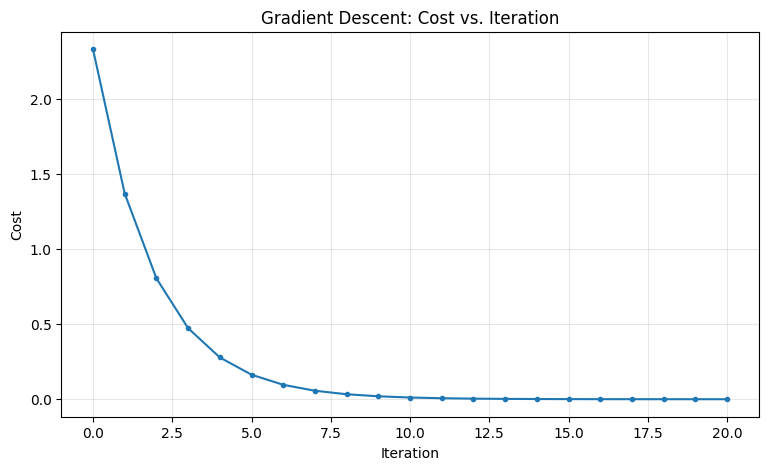

In [4]:
plt.figure(figsize=(9, 5))

plt.plot(
    history["Iteration"],
    history["Cost"],
    marker="o",
    markersize=3
)

plt.xlabel("Iteration")
plt.ylabel("Cost")
plt.title("Gradient Descent: Cost vs. Iteration")
plt.grid(True, alpha=0.3)
plt.show()

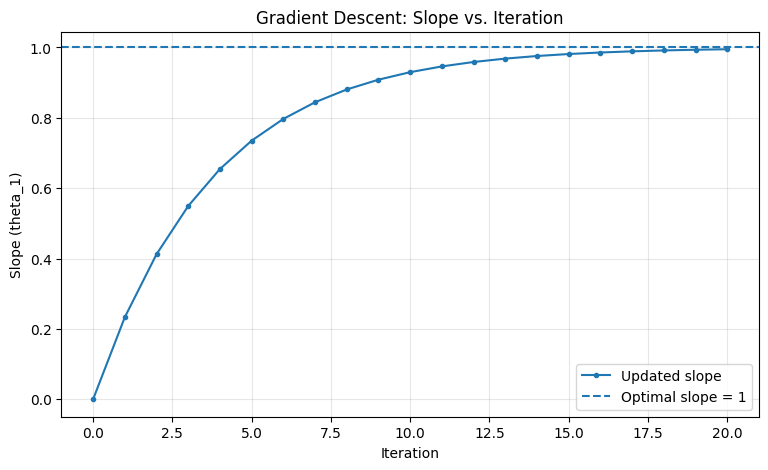

In [5]:
plt.figure(figsize=(9, 5))

plt.plot(
    history["Iteration"],
    history["Slope"],
    marker="o",
    markersize=3,
    label="Updated slope"
)

plt.axhline(
    y=1,
    linestyle="--",
    label="Optimal slope = 1"
)

plt.xlabel("Iteration")
plt.ylabel("Slope (theta_1)")
plt.title("Gradient Descent: Slope vs. Iteration")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## 3. Understanding the Learning Rate

The learning rate controls how far the parameter moves during each update.

$$
\theta_1^{\text{new}}
=
\theta_1^{\text{old}}
-
\alpha\frac{dJ}{d\theta_1}
$$

We will compare several learning rates using the same initial slope and number of iterations.

A small learning rate may converge slowly. A sufficiently large learning rate may reach the minimum faster, while an excessively large one can cause oscillation or divergence.

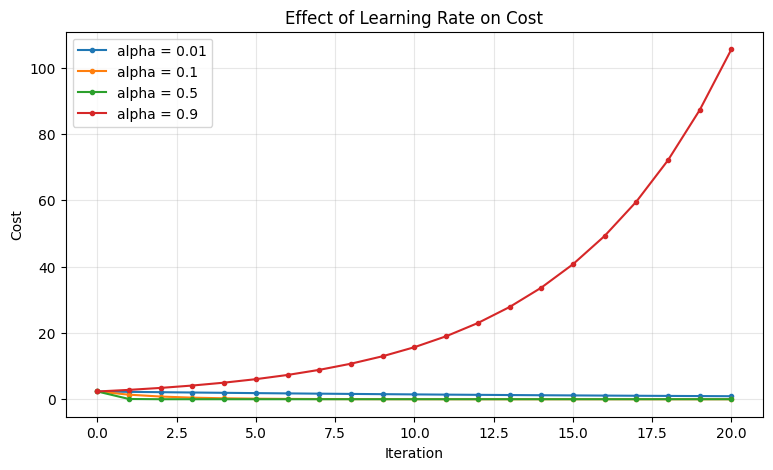

In [6]:
learning_rates = [0.01, 0.1, 0.5, 0.9]

plt.figure(figsize=(9, 5))

for alpha in learning_rates:
    _, rate_history = gradient_descent(
        initial_theta_1=0,
        learning_rate=alpha,
        iterations=20
    )

    plt.plot(
        rate_history["Iteration"],
        rate_history["Cost"],
        marker=".",
        label=f"alpha = {alpha}"
    )

plt.xlabel("Iteration")
plt.ylabel("Cost")
plt.title("Effect of Learning Rate on Cost")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [7]:
# An intentionally excessive learning rate
unstable_slope, unstable_history = gradient_descent(
    initial_theta_1=0,
    learning_rate=1.0,
    iterations=10
)

unstable_history[["Iteration", "Slope", "Gradient", "Cost"]].round(4)

,Iteration,Slope,Gradient,Cost
0,0,0.0000,-2.3333,2.3333
1,1,2.3333,3.1111,4.1481
2,2,-0.7778,-4.1481,7.3745
3,3,3.3704,5.5309,13.1102
4,4,-2.1605,-7.3745,23.3070
5,5,5.2140,9.8326,41.4347
6,6,-4.6187,-13.1102,73.6617
7,7,8.4915,17.4803,130.9541
8,8,-8.9887,-23.3070,232.8073
9,9,14.3183,31.0760,413.8796


## 4. Understanding Convergence

Convergence occurs when the optimization process reaches its stopping condition or the updates become sufficiently small.

We can monitor:

- Cost change between iterations.
- Parameter change between iterations.
- Maximum iteration count.

A low cost or small update does not automatically prove that every possible optimization problem has reached its global minimum. In this example, however, the cost is a convex quadratic function with a known global minimum at $\theta_1=1$.

In [8]:
def gradient_descent_until_convergence(
    initial_theta_1,
    learning_rate,
    tolerance=1e-6,
    max_iterations=10_000
):
    theta_1 = float(initial_theta_1)
    history = []

    for iteration in range(max_iterations + 1):
        cost = compute_cost(
            data["x"],
            data["y"],
            theta_0=0,
            theta_1=theta_1
        )

        gradient = compute_gradient(theta_1)

        history.append({
            "Iteration": iteration,
            "Slope": theta_1,
            "Gradient": gradient,
            "Cost": cost
        })

        if abs(gradient) < tolerance:
            break

        new_theta_1 = theta_1 - learning_rate * gradient

        if abs(new_theta_1 - theta_1) < tolerance:
            theta_1 = new_theta_1
            break

        theta_1 = new_theta_1

    return theta_1, pd.DataFrame(history)


converged_slope, convergence_history = (
    gradient_descent_until_convergence(
        initial_theta_1=0,
        learning_rate=0.1
    )
)

print(f"Converged slope: {converged_slope:.8f}")
print(f"Final cost:      {convergence_history['Cost'].iloc[-1]:.10f}")
print(f"Iterations:      {len(convergence_history) - 1}")

Converged slope: 0.99999711
Final cost:      0.0000000000
Iterations:      47


## 5. Self-Check

1. What does the derivative tell us?
2. What is the purpose of the learning rate?
3. Why does a negative gradient increase the parameter?
4. What can happen when the learning rate is too large?
5. What is the global minimum in our simplified example?
6. Why must the gradient be recalculated after each update?
7. Does convergence always guarantee a global minimum?
8. Which values are fixed in this notebook, and which parameter is updated?

### Answers

1. The local rate and direction of change in cost.
2. It controls the size of each parameter update.
3. The update subtracts a negative gradient, increasing the parameter.
4. Updates may overshoot, oscillate, or diverge.
5. Slope = 1 and cost = 0.
6. The gradient changes as the parameter changes.
7. No. It depends on the optimization problem.
8. The intercept is fixed at zero; only the slope is updated.

# Gradient Descent and Convergence

## Learning Objectives

By the end of this notebook, you will be able to:

- Implement the gradient descent algorithm.
- Understand how derivatives determine the update direction.
- Experiment with different learning rates.
- Track cost across iterations.
- Understand convergence and stopping conditions.
- Visualize how gradient descent approaches the minimum.

**Dataset:** Three observations: (1, 1), (2, 2), and (3, 3).

For this simplified example, the intercept is fixed at $\theta_0 = 0$, and only the slope $\theta_1$ is updated.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

data = pd.DataFrame({
    "x": [1, 2, 3],
    "y": [1, 2, 3]
})

display(data)


,x,y
0,1,1
1,2,2
2,3,3


## 1. Prediction Function

The hypothesis for simple linear regression is:

$$
h_\theta(x) = \theta_0 + \theta_1x
$$

Since the intercept is fixed at zero:

$$
h_\theta(x) = \theta_1x
$$

We will use this function to calculate predictions at each iteration.


In [2]:
def predict_output(x, theta_0, theta_1):
    return theta_0 + theta_1 * x


# Example prediction
theta_0 = 0
theta_1 = 0.5

predictions = predict_output(
    data["x"],
    theta_0,
    theta_1
)

print("Predictions:", predictions.tolist())


Predictions: [0.5, 1.0, 1.5]


## 2. Cost Function

We use the half mean squared-error cost:

$$
J(\theta_1) =
\frac{1}{2m}\sum_{i=1}^{m}
\left(\theta_1x^{(i)}-y^{(i)}\right)^2
$$

The objective is to find the slope that minimizes this cost.


In [3]:
def compute_cost(x, y, theta_0, theta_1):
    predictions = predict_output(x, theta_0, theta_1)
    errors = predictions - y

    m = len(y)
    cost = np.sum(errors ** 2) / (2 * m)

    return cost


for slope in [0, 0.5, 1]:
    cost = compute_cost(
        data["x"],
        data["y"],
        theta_0=0,
        theta_1=slope
    )

    print(f"Slope: {slope:.1f} | Cost: {cost:.4f}")


Slope: 0.0 | Cost: 2.3333
Slope: 0.5 | Cost: 0.5833
Slope: 1.0 | Cost: 0.0000


## 3. Calculate the Gradient

The derivative of the cost function with respect to the slope is:

$$
\frac{dJ}{d\theta_1}
=
\frac{1}{m}\sum_{i=1}^{m}
(\theta_1x^{(i)}-y^{(i)})x^{(i)}
$$

For this dataset, the derivative simplifies to:

$$
\frac{dJ}{d\theta_1}
=
\frac{7}{3}(\theta_1-1)
$$

The derivative determines the direction of the update:

- Negative derivative → increase the slope.
- Positive derivative → decrease the slope.
- Zero derivative → no gradient-based change.


In [4]:
def compute_gradient(x, y, theta_0, theta_1):
    predictions = predict_output(x, theta_0, theta_1)
    errors = predictions - y

    m = len(y)

    gradient = np.sum(errors * x) / m

    return gradient


for slope in [0, 0.5, 1, 1.5]:
    gradient = compute_gradient(
        data["x"],
        data["y"],
        theta_0=0,
        theta_1=slope
    )

    print(f"Slope: {slope:.1f} | Gradient: {gradient:.4f}")


Slope: 0.0 | Gradient: -4.6667
Slope: 0.5 | Gradient: -2.3333
Slope: 1.0 | Gradient: 0.0000
Slope: 1.5 | Gradient: 2.3333


## 4. Gradient Descent Algorithm

The update rule is:

$$
\theta_1 \leftarrow
\theta_1-\alpha\frac{dJ}{d\theta_1}
$$

At each iteration:

1. Calculate the current cost and gradient.
2. Record the current values.
3. Update the slope.
4. Repeat for the specified number of iterations.

We record the cost before each update, including the initial cost and the final cost, to track optimization progress.


In [5]:
def gradient_descent(
    x,
    y,
    initial_theta_1=0,
    learning_rate=0.1,
    iterations=20
):
    theta_1 = initial_theta_1
    history = []

    for iteration in range(iterations + 1):
        cost = compute_cost(
            x, y,
            theta_0=0,
            theta_1=theta_1
        )

        gradient = compute_gradient(
            x, y,
            theta_0=0,
            theta_1=theta_1
        )

        history.append({
            "iteration": iteration,
            "theta_1": theta_1,
            "gradient": gradient,
            "cost": cost
        })

        if iteration < iterations:
            theta_1 = theta_1 - learning_rate * gradient

    return theta_1, pd.DataFrame(history)


final_slope, history = gradient_descent(
    data["x"],
    data["y"],
    initial_theta_1=0,
    learning_rate=0.1,
    iterations=20
)

print(f"Final slope: {final_slope:.6f}")
print(f"Final cost: {history['cost'].iloc[-1]:.8f}")

display(history.head())
display(history.tail())


Final slope: 0.999997
Final cost: 0.00000000


,iteration,theta_1,gradient,cost
0,0,0.000000,-4.666667,2.333333
1,1,0.466667,-2.488889,0.663704
2,2,0.715556,-1.327407,0.188787
3,3,0.848296,-0.707951,0.053699
4,4,0.919091,-0.377574,0.015274


,iteration,theta_1,gradient,cost
16,16,0.999957,-0.000200,4.284855e-09
17,17,0.999977,-0.000107,1.218803e-09
18,18,0.999988,-0.000057,3.466818e-10
19,19,0.999993,-0.000030,9.861170e-11
20,20,0.999997,-0.000016,2.804955e-11


## 5. Cost Reduction

A successful sequence of gradient descent updates should reduce the cost toward its minimum.

Let's plot the cost at each iteration to observe the optimization process.


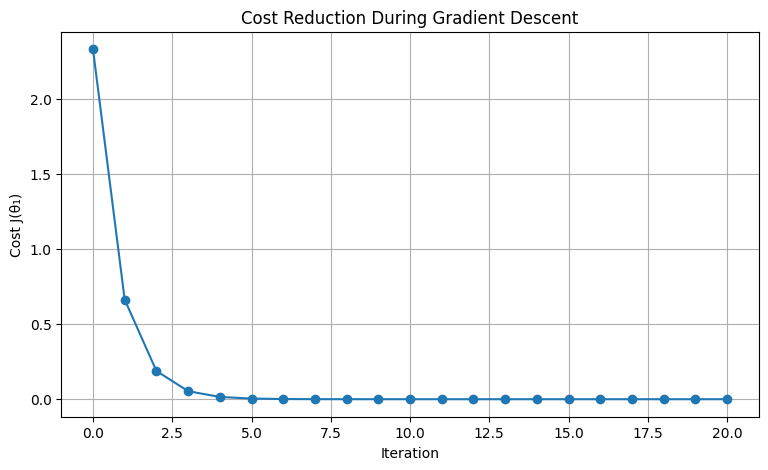

In [6]:
plt.figure(figsize=(9, 5))

plt.plot(
    history["iteration"],
    history["cost"],
    marker="o"
)

plt.xlabel("Iteration")
plt.ylabel("Cost J(θ₁)")
plt.title("Cost Reduction During Gradient Descent")
plt.grid(True)
plt.show()


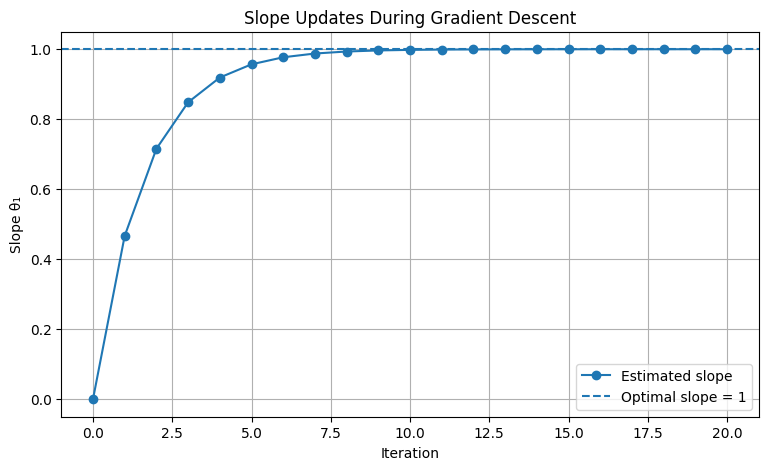

In [7]:
plt.figure(figsize=(9, 5))

plt.plot(
    history["iteration"],
    history["theta_1"],
    marker="o",
    label="Estimated slope"
)

plt.axhline(
    y=1,
    linestyle="--",
    label="Optimal slope = 1"
)

plt.xlabel("Iteration")
plt.ylabel("Slope θ₁")
plt.title("Slope Updates During Gradient Descent")
plt.legend()
plt.grid(True)
plt.show()


## 6. Effect of the Learning Rate

The learning rate controls the size of each update.

We will compare:

- `0.001` — small updates.
- `0.01` — gradual updates.
- `0.1` — faster updates for this example.
- `0.5` — larger updates.

These are illustrative values. Their behavior depends on the cost function and parameter scale.

Observe how quickly each learning rate reduces the cost.


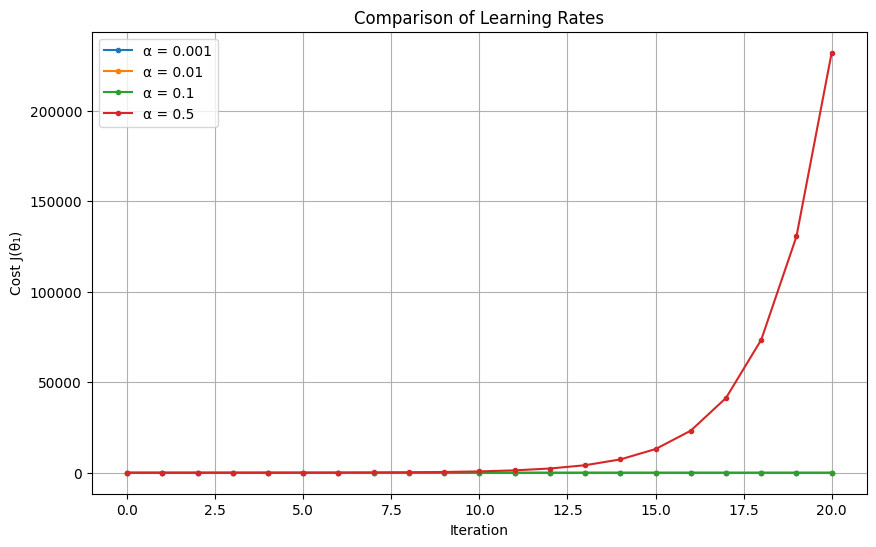

In [8]:
learning_rates = [0.001, 0.01, 0.1, 0.5]

plt.figure(figsize=(10, 6))

for alpha in learning_rates:
    _, rate_history = gradient_descent(
        data["x"],
        data["y"],
        initial_theta_1=0,
        learning_rate=alpha,
        iterations=20
    )

    plt.plot(
        rate_history["iteration"],
        rate_history["cost"],
        marker=".",
        label=f"α = {alpha}"
    )

plt.xlabel("Iteration")
plt.ylabel("Cost J(θ₁)")
plt.title("Comparison of Learning Rates")
plt.legend()
plt.grid(True)
plt.show()


## 7. Gradient Descent Until Convergence

Instead of always running a fixed number of iterations, we can stop when the gradient magnitude becomes sufficiently small.

For this example, the stopping condition is:

$$
\left|\frac{dJ}{d\theta_1}\right| < \varepsilon
$$

Here, $\varepsilon$ is a small tolerance value.

We also impose a maximum iteration limit to prevent an endless loop. Reaching the tolerance indicates that the gradient is small; it does not automatically guarantee a global minimum for every optimization problem.


In [10]:
def gradient_descent_until_convergence(
    x,
    y,
    initial_theta_1=0,
    learning_rate=0.1,
    tolerance=1e-6,
    max_iterations=10000
):
    theta_1 = initial_theta_1
    history = []

    for iteration in range(max_iterations + 1):
        cost = compute_cost(
            x, y,
            theta_0=0,
            theta_1=theta_1
        )

        gradient = compute_gradient(
            x, y,
            theta_0=0,
            theta_1=theta_1
        )

        history.append({
            "iteration": iteration,
            "theta_1": theta_1,
            "gradient": gradient,
            "cost": cost
        })

        if abs(gradient) < tolerance:
            break

        if iteration == max_iterations:
            break

        theta_1 = theta_1 - learning_rate * gradient

    result = pd.DataFrame(history)

    converged = abs(result["gradient"].iloc[-1]) < tolerance

    return theta_1, result, converged


final_slope, convergence_history, converged = (
    gradient_descent_until_convergence(
        data["x"],
        data["y"],
        initial_theta_1=0,
        learning_rate=0.1,
        tolerance=1e-6,
        max_iterations=10000
    )
)

print(f"Final slope: {final_slope:.8f}")
print(f"Final cost: {convergence_history['cost'].iloc[-1]:.10f}")
print(f"Iterations: {convergence_history['iteration'].iloc[-1]}")
print(f"Converged: {converged}")

display(convergence_history.tail())


Final slope: 0.99999985
Final cost: 0.0000000000
Iterations: 25
Converged: True


,iteration,theta_1,gradient,cost
21,21,0.999998,-8.629389e-06,7.978539e-12
22,22,0.999999,-4.602341e-06,2.269451e-12
23,23,0.999999,-2.454582e-06,6.455327e-13
24,24,1.000000,-1.309110e-06,1.836182e-13
25,25,1.000000,-6.981922e-07,5.222918e-14


## 8. Self-Check Questions

Try answering these before running the answer cell.

1. Why is gradient descent more systematic than manually trying parameter values?
2. What happens when the derivative is negative?
3. What is the purpose of the learning rate?
4. Why can an excessively large learning rate be problematic?
5. What stopping condition does our implementation use?
6. What is the optimal slope for our dataset?
7. Does a small gradient always guarantee a global minimum?

### Answers

1. It updates the parameter systematically using the cost gradient.
2. The parameter increases after subtracting a negative gradient.
3. It controls the size of each parameter update.
4. Updates may overshoot the minimum or fail to converge.
5. The absolute gradient must be smaller than the chosen tolerance, or the maximum iteration limit is reached.
6. The optimal slope is 1 for this dataset when the intercept is fixed at zero.
7. No. A small gradient can also occur at a local minimum, maximum, or stationary point, depending on the objective.

